In [1]:
import itertools
import numpy as np
import pandas as pd
import glob, os
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D                             


# print(os.getcwd())
# print(os.listdir("."))

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

# Method section 3.4. Fitting the constants

## - Possible groups out of 8 specialist

In [2]:
from math import comb
print(comb(8, 3)) 
print(comb(8, 4)) 
print(comb(8, 5)) 
print(comb(8, 6)) 
print(comb(8, 7))
print(comb(8, 8)) 

56
70
56
28
8
1


## - Fitting c0 and c1

In [3]:
files = sorted(f for f in glob.glob("*.csv")
               if f.startswith(("bi-encoder_", "colbert_", "cross-encoder_")))
print(len(files), "files found")

for path in files:
    S = pd.read_csv(path).filter(like="_scores").values
    print(os.path.basename(path), S.shape)

14 files found
bi-encoder_BAAI-bge-large-en-v1.5.csv (100, 8)
bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv (100, 8)
bi-encoder_Qwen-Qwen3-Embedding-4B.csv (100, 8)
bi-encoder_Qwen-Qwen3-Embedding-8B.csv (100, 8)
bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv (100, 8)
colbert_LiquidAI-LFM2-ColBERT-350M.csv (100, 8)
colbert_colbert-ir-colbertv2.0.csv (100, 8)
colbert_lightonai-Reason-ModernColBERT.csv (100, 8)
colbert_mixedbread-ai-mxbai-colbert-large-v1.csv (100, 8)
cross-encoder_BAAI-bge-reranker-v2-m3.csv (100, 8)
cross-encoder_Qwen-Qwen3-Reranker-0.6B.csv (100, 8)
cross-encoder_Qwen-Qwen3-Reranker-4B.csv (100, 8)
cross-encoder_Qwen-Qwen3-Reranker-8B.csv (100, 8)
cross-encoder_mixedbread-ai-mxbai-rerank-large-v2.csv (100, 8)


In [4]:
# 1. average function

def average_cutoffs(scores, ks=range(3, 9), percentile=90, show=False): 
    number_of_specialists = scores.shape[1]            # 8
    average_cutoff_for_k = {}

    for k in ks:                                        # for each group size
        cutoffs_for_this_k = []                         # one cutoff per group of size k

        # every way to pick k specialists out of the 8
        for i, chosen_columns in enumerate(itertools.combinations(range(number_of_specialists), k)):

            # take all rows, but for chosen columns only
            chosen_scores = scores.iloc[:, list(chosen_columns)]

            # for each query: best score minus the typical (median) score
            best_score   = chosen_scores.max(axis=1)           # one number per query
            median_score = chosen_scores.median(axis=1)        # one number per query
            gap = best_score - median_score                    # one gap per query

            # the cutoff for this group: the 90th percentile of the 100 gaps
            cutoff = gap.quantile(percentile / 100)
            cutoffs_for_this_k.append(cutoff)

            # print the first group of each size, to see the steps
            if show and i == 0:
                print(f"--- k={k}, first group = columns {chosen_columns} ---")
                print("scores of the first 3 queries:")
                print(chosen_scores.head(3).round(3))
                print("best score:  ", best_score.head(3).round(3).tolist())
                print("median score:", median_score.head(3).round(3).tolist())
                print("gap:         ", gap.head(3).round(3).tolist())
                print(f"90th percentile of the {len(gap)} gaps = {cutoff:.4f}")

        # average the cutoffs over all the groups of size k
        average_cutoff_for_k[k] = sum(cutoffs_for_this_k) / len(cutoffs_for_this_k)

        if show:
            print(f"k={k}: {len(cutoffs_for_this_k)} groups, average cutoff = {average_cutoff_for_k[k]:.4f}\n")

    return pd.DataFrame([average_cutoff_for_k], index=["Average cutoff"]).rename_axis("k", axis=1)

In [5]:
# S = pd.read_csv(files[0]).filter(like="_scores")      
# print(average_cutoffs(S))

In [6]:
# 2. then the loop over the 14 model files

files = sorted(f for f in glob.glob("*.csv")
               if f.startswith(("bi-encoder_", "colbert_", "cross-encoder_")))

percentiles = [90]
all_rows = []

for file_name in files:
    df = pd.read_csv(file_name)
    scores = df.filter(like="_scores")                  # no .values: keep it a table

    for p in percentiles:
        table = average_cutoffs(scores, percentile=p)
        table.insert(0, "model", file_name)
        table.insert(1, "percentile", p)
        all_rows.append(table)

average_cutoff_table = pd.concat(all_rows, ignore_index=True)
# average_cutoff_table.to_csv("average_cutoffs_k3_8.csv", index=False)
average_cutoff_table

k,model,percentile,3,4,5,6,7,8
0,bi-encoder_BAAI-bge-large-en-v1.5.csv,90,0.061609,0.064933,0.071063,0.073761,0.075758,0.076381
1,bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv,90,0.104772,0.111568,0.120244,0.123677,0.127373,0.129968
2,bi-encoder_Qwen-Qwen3-Embedding-4B.csv,90,0.094074,0.102701,0.114553,0.119332,0.127957,0.129950
3,bi-encoder_Qwen-Qwen3-Embedding-8B.csv,90,0.089237,0.097338,0.108694,0.112027,0.117252,0.120252
4,bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv,90,0.095763,0.102555,0.112373,0.116323,0.122901,0.128221
5,colbert_LiquidAI-LFM2-ColBERT-350M.csv,90,0.000984,0.001112,0.001261,0.001332,0.001454,0.001490
6,colbert_colbert-ir-colbertv2.0.csv,90,0.062483,0.067846,0.076934,0.080269,0.083726,0.083598
7,colbert_lightonai-Reason-ModernColBERT.csv,90,0.024361,0.027357,0.031380,0.032896,0.035431,0.037408
8,colbert_mixedbread-ai-mxbai-colbert-large-v1.csv,90,0.100558,0.104932,0.113966,0.116281,0.120428,0.119298
9,cross-encoder_BAAI-bge-reranker-v2-m3.csv,90,0.000054,0.000070,0.000083,0.000095,0.000104,0.000116


bi-encoder_BAAI-bge-large-en-v1.5.csv  p=90
   measured: [0.0616 0.0649 0.0711 0.0738 0.0758 0.0764]
   fitted:   [0.0616 0.0662 0.0699 0.0729 0.0754 0.0776]
   c0=0.0436  c1=0.0163  R2=0.970

bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv  p=90
   measured: [0.1048 0.1116 0.1202 0.1237 0.1274 0.13  ]
   fitted:   [0.105  0.1126 0.1185 0.1233 0.1274 0.1309]
   c0=0.0760  c1=0.0264  R2=0.989

bi-encoder_Qwen-Qwen3-Embedding-4B.csv  p=90
   measured: [0.0941 0.1027 0.1146 0.1193 0.128  0.13  ]
   fitted:   [0.0935 0.1045 0.1131 0.1201 0.1261 0.1312]
   c0=0.0512  c1=0.0385  R2=0.988

bi-encoder_Qwen-Qwen3-Embedding-8B.csv  p=90
   measured: [0.0892 0.0973 0.1087 0.112  0.1173 0.1203]
   fitted:   [0.0895 0.0988 0.1061 0.112  0.117  0.1214]
   c0=0.0537  c1=0.0325  R2=0.986

bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv  p=90
   measured: [0.0958 0.1026 0.1124 0.1163 0.1229 0.1282]
   fitted:   [0.0946 0.1042 0.1116 0.1177 0.1228 0.1273]
   c0=0.0580  c1=0.0333  R2=0.990

colbert_Liquid

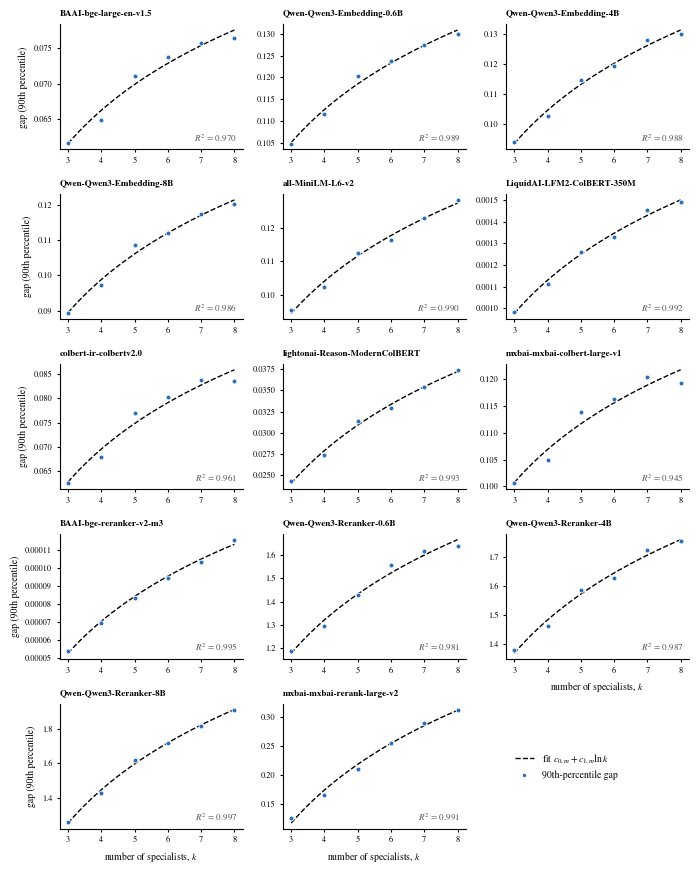

,model,percentile,c0,c1,R2
0,bi-encoder_BAAI-bge-large-en-v1.5.csv,90,0.043623,0.016321,0.970275
1,bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv,90,0.076034,0.026373,0.988926
2,bi-encoder_Qwen-Qwen3-Embedding-4B.csv,90,0.051210,0.038472,0.988415
3,bi-encoder_Qwen-Qwen3-Embedding-8B.csv,90,0.053732,0.032529,0.985510
4,bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv,90,0.058012,0.033301,0.990168
5,colbert_LiquidAI-LFM2-ColBERT-350M.csv,90,0.000387,0.000536,0.992223
6,colbert_colbert-ir-colbertv2.0.csv,90,0.036888,0.023561,0.960919
7,colbert_lightonai-Reason-ModernColBERT.csv,90,0.009360,0.013386,0.992747
8,colbert_mixedbread-ai-mxbai-colbert-large-v1.csv,90,0.077122,0.021463,0.944732
9,cross-encoder_BAAI-bge-reranker-v2-m3.csv,90,-0.000015,0.000062,0.994993


In [10]:
# 3. Finding c0 and c1 

ks = np.arange(3, 9)                     # the pool sizes: 3, 4, 5, 6, 7, 8
rows = []                                # one result per (model, percentile)
fits = {} 

# go through the table one row at a time
# each row = one model at one percentile, with six measured numbers (k = 3 ... 8)
# for row_number, row in average_cutoff_table.iterrows():
for row_number, row in average_cutoff_table[average_cutoff_table["percentile"] == 90].iterrows():
    
    model_name = row["model"]
    percentile = row["percentile"]

    # the six measured cutoffs of this row
    measured = row[[3, 4, 5, 6, 7, 8]].astype(float).values

    # fit the line  measured = c0 + c1 * ln(k)
    c1, c0 = np.polyfit(np.log(ks), measured, 1)

    
    fitted = c0 + c1 * np.log(ks)
    r2 = 1 - ((measured - fitted) ** 2).sum() / ((measured - measured.mean()) ** 2).sum()

    # print what happened for this row
    print(f"{model_name}  p={percentile}")
    print(f"   measured: {np.round(measured, 4)}")
    print(f"   fitted:   {np.round(fitted, 4)}")
    print(f"   c0={c0:.4f}  c1={c1:.4f}  R2={r2:.3f}\n")

    rows.append({"model": model_name, "percentile": percentile,
                 "c0": c0, "c1": c1, "R2": r2})
    fits[model_name] = (measured, c0, c1, r2)   

constants = pd.DataFrame(rows)


# ---- figure: one panel per model ----
plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42,
                     "font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7,
                     "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 7})

BLUE = "#2a6fbb"

def short_name(file_name):
    name = file_name.replace(".csv", "").split("_", 1)[1]            # drop the family prefix and ".csv"
    return name.replace("sentence-transformers-", "").replace("mixedbread-ai-", "mxbai-")

n_cols = 3
n_rows = int(np.ceil(len(fits) / n_cols))                            # 14 models -> 4 rows

fine_k = np.linspace(3, 8, 100)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7.0, 1.75 * n_rows))
axes = axes.ravel()

for ax, (f, (tau, c0, c1, r2)) in zip(axes, fits.items()):
    ax.plot(fine_k, c0 + c1 * np.log(fine_k), "--", color="black", lw=1.0)
    ax.plot(ks, tau, "o", color=BLUE, ms=3.5, mec="white", mew=0.6)
    ax.set_title(short_name(f), loc="left", fontsize=6.5, fontweight="bold")
    ax.set_xticks(ks)
    ax.tick_params(length=2)
    ax.text(0.97, 0.06, f"$R^2$ = {r2:.3f}", transform=ax.transAxes,
            ha="right", fontsize=6.5, color="#52514e")
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[len(fits):]:                                          # hide the empty panels
    ax.axis("off")

# legend in the first empty panel
spare = axes[len(fits)]
handles = [plt.Line2D([0], [0], ls="--", color="black", lw=1,
                      label=r"fit $c_{0,m}+c_{1,m}\ln k$"),
           plt.Line2D([0], [0], marker="o", ls="", color=BLUE, ms=3.5, mec="white",
                      label="90th-percentile gap")]
spare.legend(handles=handles, frameon=False, loc="center left")

for ax in axes[len(fits) - n_cols:len(fits)]:                        # x label on the bottom panels
    ax.set_xlabel("number of specialists, $k$")
for r in range(n_rows):
    axes[r * n_cols].set_ylabel("gap (90th percentile)")

fig.tight_layout(w_pad=1.0, h_pad=1.0)
fig.savefig("cutoff_fit_all.pdf", bbox_inches="tight")
fig.savefig("cutoff_fit_all.png", dpi=600, bbox_inches="tight")
plt.show()


constants

## - collapse figure (rescaling to see all models)

In [8]:
# 4. Rescaling: two formulas

p = 90
table_p = average_cutoff_table[average_cutoff_table["percentile"] == p]

# one table with the measured values AND c0, c1 for each model
both = table_p.merge(constants, on=["model", "percentile"])
both

,model,percentile,3,4,5,6,7,8,c0,c1,R2
0,bi-encoder_BAAI-bge-large-en-v1.5.csv,90,0.061609,0.064933,0.071063,0.073761,0.075758,0.076381,0.043623,0.016321,0.970275
1,bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv,90,0.104772,0.111568,0.120244,0.123677,0.127373,0.129968,0.076034,0.026373,0.988926
2,bi-encoder_Qwen-Qwen3-Embedding-4B.csv,90,0.094074,0.102701,0.114553,0.119332,0.127957,0.129950,0.051210,0.038472,0.988415
3,bi-encoder_Qwen-Qwen3-Embedding-8B.csv,90,0.089237,0.097338,0.108694,0.112027,0.117252,0.120252,0.053732,0.032529,0.985510
4,bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv,90,0.095763,0.102555,0.112373,0.116323,0.122901,0.128221,0.058012,0.033301,0.990168
5,colbert_LiquidAI-LFM2-ColBERT-350M.csv,90,0.000984,0.001112,0.001261,0.001332,0.001454,0.001490,0.000387,0.000536,0.992223
6,colbert_colbert-ir-colbertv2.0.csv,90,0.062483,0.067846,0.076934,0.080269,0.083726,0.083598,0.036888,0.023561,0.960919
7,colbert_lightonai-Reason-ModernColBERT.csv,90,0.024361,0.027357,0.031380,0.032896,0.035431,0.037408,0.009360,0.013386,0.992747
8,colbert_mixedbread-ai-mxbai-colbert-large-v1.csv,90,0.100558,0.104932,0.113966,0.116281,0.120428,0.119298,0.077122,0.021463,0.944732
9,cross-encoder_BAAI-bge-reranker-v2-m3.csv,90,0.000054,0.000070,0.000083,0.000095,0.000104,0.000116,-0.000015,0.000062,0.994993


bi-encoder_BAAI-bge-large-en-v1.5.csv | [1.1  1.31 1.68 1.85 1.97 2.01]
bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv | [1.09 1.35 1.68 1.81 1.95 2.05]
bi-encoder_Qwen-Qwen3-Embedding-4B.csv | [1.11 1.34 1.65 1.77 1.99 2.05]
bi-encoder_Qwen-Qwen3-Embedding-8B.csv | [1.09 1.34 1.69 1.79 1.95 2.04]
bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv | [1.13 1.34 1.63 1.75 1.95 2.11]
colbert_LiquidAI-LFM2-ColBERT-350M.csv | [1.11 1.35 1.63 1.76 1.99 2.06]
colbert_colbert-ir-colbertv2.0.csv | [1.09 1.31 1.7  1.84 1.99 1.98]
colbert_lightonai-Reason-ModernColBERT.csv | [1.12 1.34 1.65 1.76 1.95 2.1 ]
colbert_mixedbread-ai-mxbai-colbert-large-v1.csv | [1.09 1.3  1.72 1.82 2.02 1.97]
cross-encoder_BAAI-bge-reranker-v2-m3.csv | [1.12 1.37 1.59 1.78 1.92 2.12]
cross-encoder_Qwen-Qwen3-Reranker-0.6B.csv | [1.11 1.33 1.6  1.86 1.98 2.02]
cross-encoder_Qwen-Qwen3-Reranker-4B.csv | [1.12 1.33 1.65 1.75 1.99 2.06]
cross-encoder_Qwen-Qwen3-Reranker-8B.csv | [1.11 1.36 1.64 1.79 1.94 2.08]
cross-encoder_

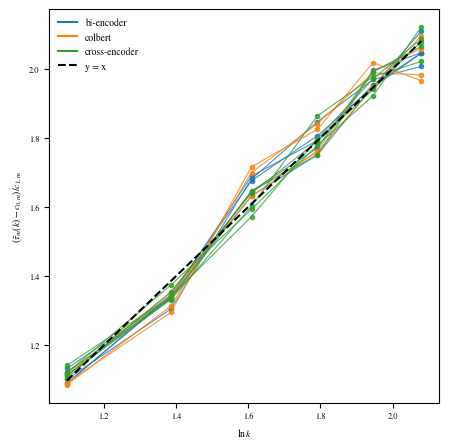

In [9]:
# 4. Rescaling and figure: choose the formula here


# Font: STIX (Times-style serif, comes with matplotlib)
plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    "pdf.fonttype": 42,
})

mode = "lnk"                  # "lnk"  or  "lnk_over_3"

p = 90
table_p = average_cutoff_table[average_cutoff_table["percentile"] == p]
both = table_p.merge(constants, on=["model", "percentile"])      # measured values + c0, c1

# the x values and the label depend on the mode
if mode == "lnk":
    x = np.log(ks)                                               # x = ln k
    xlabel = r"$\ln k$"
    ylabel = r"$(\bar\tau_m(k)-c_{0,m})/c_{1,m}$"
else:
    x = np.log(ks / 3)                                           # x = ln(k/3)
    xlabel = r"$\ln(k/3)$"
    ylabel = r"$(\bar\tau_m(k)-\bar\tau_m(3))/c_{1,m}$"

# one colour per model family
family_colors = {"bi-encoder": "tab:blue", "colbert": "tab:orange", "cross-encoder": "tab:green"}

fig, ax = plt.subplots(figsize=(4.5, 4.5))
distances = []

for i in range(len(both)):
    row = both.iloc[i]

    measured = row[[3, 4, 5, 6, 7, 8]].astype(float).values      # measured values
    c0, c1 = row["c0"], row["c1"]                                # constants, same row

    if mode == "lnk":
        y = (measured - c0) / c1                                 # formula 1
    else:
        y = (measured - measured[0]) / c1                        # formula 2

    family = row["model"].split("_")[0]                          # "bi-encoder", "colbert" or "cross-encoder"

    print(row["model"], "|", np.round(y, 2))
    ax.plot(x, y, marker="o", ms=3, lw=0.8, alpha=0.8, color=family_colors[family])
    distances.append(np.abs(y - x).max())

print("\ntarget x:", np.round(x, 2))
print(f"largest distance from y = x: {max(distances):.3f}, median: {np.median(distances):.3f}")

ax.plot(x, x, "k--")                                             # the line the points should follow
ax.set_xlabel(xlabel)
ax.set_ylabel(ylabel)

# legend: three families + the dashed line
handles = [Line2D([0], [0], color=c, lw=1.5, label=f) for f, c in family_colors.items()]
handles.append(Line2D([0], [0], color="k", ls="--", label="y = x"))
ax.legend(handles=handles, frameon=False)

plt.tight_layout()
plt.savefig(f"collapse_{mode}.pdf", bbox_inches="tight")
plt.savefig(f"collapse_{mode}.png", dpi=600, bbox_inches="tight")
plt.show()

# Why ln(k)? max grow median stable for off topics

In [2]:
import glob, itertools, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
# get the files and sorted 
files = sorted(f for f in glob.glob("*.csv") if f.startswith(("bi-encoder_", "colbert_", "cross-encoder_")))
files

['bi-encoder_BAAI-bge-large-en-v1.5.csv',
 'bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv',
 'bi-encoder_Qwen-Qwen3-Embedding-4B.csv',
 'bi-encoder_Qwen-Qwen3-Embedding-8B.csv',
 'bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv',
 'colbert_LiquidAI-LFM2-ColBERT-350M.csv',
 'colbert_colbert-ir-colbertv2.0.csv',
 'colbert_lightonai-Reason-ModernColBERT.csv',
 'colbert_mixedbread-ai-mxbai-colbert-large-v1.csv',
 'cross-encoder_BAAI-bge-reranker-v2-m3.csv',
 'cross-encoder_Qwen-Qwen3-Reranker-0.6B.csv',
 'cross-encoder_Qwen-Qwen3-Reranker-4B.csv',
 'cross-encoder_Qwen-Qwen3-Reranker-8B.csv',
 'cross-encoder_mixedbread-ai-mxbai-rerank-large-v2.csv']

In [6]:
# the group sizes k = 3, 4, 5, 6, 7, 8 (range stops before 9)

ks = list(range(3, 9))
ks

[3, 4, 5, 6, 7, 8]

In [8]:
def mean_max_median(scores):
    results_per_k = []
    for k in ks:
        highest_means, median_means = [], []
        for chosen_columns in itertools.combinations(range(scores.shape[1]), k):
            chosen_scores = scores[:, chosen_columns]
            highest_means.append(chosen_scores.max(axis=1).mean())
            median_means.append(np.median(chosen_scores, axis=1).mean())
        results_per_k.append((np.mean(highest_means), np.mean(median_means)))
    return np.array(results_per_k)    

In [9]:
results = {}
for f in files:
    scores = pd.read_csv(f).filter(like="_scores").values
    print(f, scores.shape)              # should print (100, 8) for every file
    results[f] = mean_max_median(scores)

bi-encoder_BAAI-bge-large-en-v1.5.csv (100, 8)
bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv (100, 8)
bi-encoder_Qwen-Qwen3-Embedding-4B.csv (100, 8)
bi-encoder_Qwen-Qwen3-Embedding-8B.csv (100, 8)
bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv (100, 8)
colbert_LiquidAI-LFM2-ColBERT-350M.csv (100, 8)
colbert_colbert-ir-colbertv2.0.csv (100, 8)
colbert_lightonai-Reason-ModernColBERT.csv (100, 8)
colbert_mixedbread-ai-mxbai-colbert-large-v1.csv (100, 8)
cross-encoder_BAAI-bge-reranker-v2-m3.csv (100, 8)
cross-encoder_Qwen-Qwen3-Reranker-0.6B.csv (100, 8)
cross-encoder_Qwen-Qwen3-Reranker-4B.csv (100, 8)
cross-encoder_Qwen-Qwen3-Reranker-8B.csv (100, 8)
cross-encoder_mixedbread-ai-mxbai-rerank-large-v2.csv (100, 8)


In [18]:
rows = []
for f, r in results.items():
    for i, k in enumerate(ks):
        rows.append({
            "model": f.replace(".csv", ""),
            "k": k,
            "highest_mean": r[i, 0],
            "median_mean": r[i, 1],
        })

scores_by_k = pd.DataFrame(rows)
scores_by_k

,model,k,highest_mean,median_mean
0,bi-encoder_BAAI-bge-large-en-v1.5,3,0.374607,0.343699
1,bi-encoder_BAAI-bge-large-en-v1.5,4,0.381138,0.343699
2,bi-encoder_BAAI-bge-large-en-v1.5,5,0.385767,0.343594
3,bi-encoder_BAAI-bge-large-en-v1.5,6,0.389285,0.343594
4,bi-encoder_BAAI-bge-large-en-v1.5,7,0.392063,0.344071
5,bi-encoder_BAAI-bge-large-en-v1.5,8,0.394292,0.344071
6,bi-encoder_Qwen-Qwen3-Embedding-0.6B,3,0.227705,0.167346
7,bi-encoder_Qwen-Qwen3-Embedding-0.6B,4,0.240134,0.167346
8,bi-encoder_Qwen-Qwen3-Embedding-0.6B,5,0.248973,0.168875
9,bi-encoder_Qwen-Qwen3-Embedding-0.6B,6,0.255723,0.168875


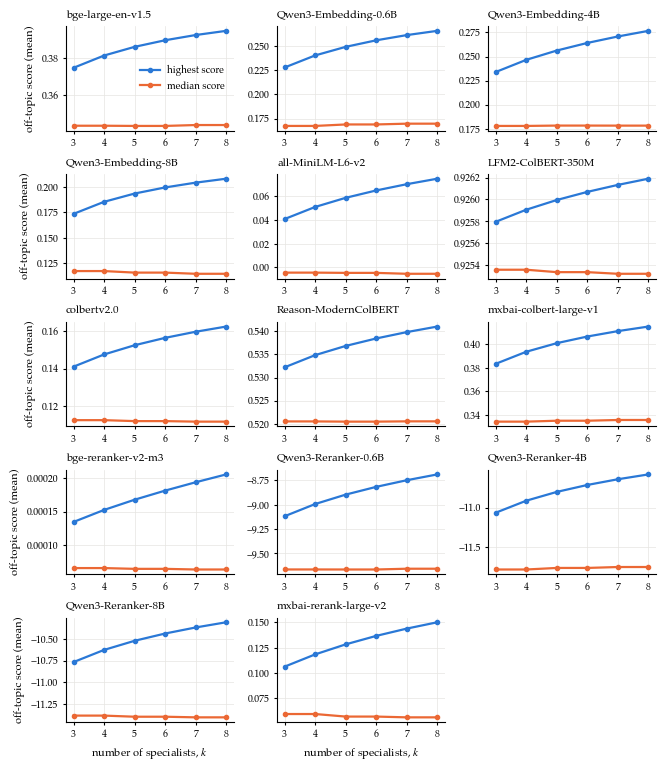

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import logging
logging.getLogger("fontTools").setLevel(logging.ERROR)

# ---- MDPI style: Palatino text, real sizes (no scaling in LaTeX) ----
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Palatino", "Palatino Linotype", "TeX Gyre Pagella", "STIXGeneral"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.titlesize": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.5,
    "axes.axisbelow": True,
    "pdf.fonttype": 42,          # embeds fonts as TrueType (journals require embedded fonts)
})
BLUE, ORANGE = "#2a78d6", "#eb6834"

def short_name(f):
    name = f.replace(".csv", "").split("_", 1)[1]
    for old in ["sentence-transformers-", "BAAI-", "Qwen-", "mixedbread-ai-",
                "LiquidAI-", "lightonai-", "colbert-ir-"]:
        name = name.replace(old, "")
    return name

n_cols = 3
n_rows = int(np.ceil(len(results) / n_cols))                # 14 models -> 5 rows
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.7, 1.55 * n_rows))   # ~17 cm wide
axes = axes.ravel()

for ax, (f, r) in zip(axes, results.items()):
    ax.plot(ks, r[:, 0], "-o", color=BLUE, lw=1.6, ms=3, label="highest score")
    ax.plot(ks, r[:, 1], "-o", color=ORANGE, lw=1.6, ms=3, label="median score")
    ax.set_title(short_name(f), loc="left", fontweight="bold")
    ax.set_xticks(ks)
    ax.tick_params(length=2)

for ax in axes[len(results):]:                              # switch off the empty panel
    ax.axis("off")

for ax in axes[-n_cols:]:                                   # x label on the bottom row only
    if ax.axison:
        ax.set_xlabel("number of specialists, $k$")
for row in range(n_rows):                                   # y label on the first column only
    axes[row * n_cols].set_ylabel("off-topic score (mean)")

axes[0].legend(frameon=False, loc="center right")
fig.tight_layout(w_pad=0.8, h_pad=0.8)
fig.savefig("max_grows_all.pdf", bbox_inches="tight")        # vector, use this in LaTeX
fig.savefig("max_grows_all.png", dpi=600, bbox_inches="tight")

In [23]:
def average_cutoff_per_k(scores, percentile=90):
    """90th-percentile gap for each k, averaged over all groups of k specialists."""
    taus = []
    for k in ks:
        per_group = []
        for chosen_columns in itertools.combinations(range(scores.shape[1]), k):
            chosen_scores = scores[:, chosen_columns]
            gap = chosen_scores.max(axis=1) - np.median(chosen_scores, axis=1)
            per_group.append(np.percentile(gap, percentile))
        taus.append(np.mean(per_group))
    return np.array(taus)

,c0,c1,R2
bge-large-en-v1.5,0.043623,0.016321,0.970275
Qwen3-Embedding-0.6B,0.076034,0.026373,0.988926
Qwen3-Embedding-4B,0.051210,0.038472,0.988415
Qwen3-Embedding-8B,0.053732,0.032529,0.985510
all-MiniLM-L6-v2,0.058012,0.033301,0.990168
LFM2-ColBERT-350M,0.000387,0.000536,0.992223
colbertv2.0,0.036888,0.023561,0.960919
Reason-ModernColBERT,0.009360,0.013386,0.992747
mxbai-colbert-large-v1,0.077122,0.021463,0.944732
bge-reranker-v2-m3,-0.000015,0.000062,0.994993


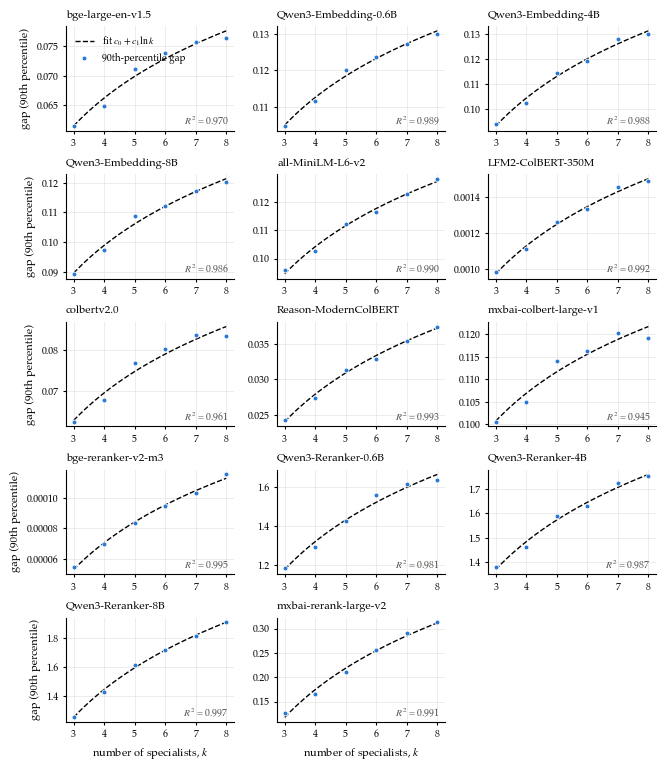

In [25]:
# cutoffs and fits for all 14 models
fits = {}
for f in files:
    scores = pd.read_csv(f).filter(like="_scores").values
    tau = average_cutoff_per_k(scores, percentile=90)
    c1, c0 = np.polyfit(np.log(ks), tau, 1)
    predicted = c0 + c1 * np.log(ks)
    r2 = 1 - ((tau - predicted) ** 2).sum() / ((tau - tau.mean()) ** 2).sum()
    fits[f] = (tau, c0, c1, r2)


    
# figure: one panel per model
fine_k = np.linspace(3, 8, 100)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.7, 1.55 * n_rows))
axes = axes.ravel()

for ax, (f, (tau, c0, c1, r2)) in zip(axes, fits.items()):
    ax.plot(fine_k, c0 + c1 * np.log(fine_k), "--", color="black", lw=1.0,
            label=r"fit $c_0+c_1\ln k$")
    ax.plot(ks, tau, "o", color=BLUE, ms=3.5, mec="white", mew=0.6,
            label="90th-percentile gap")
    ax.set_title(short_name(f), loc="left", fontweight="bold")
    ax.set_xticks(ks)
    ax.tick_params(length=2)
    ax.text(0.97, 0.06, f"$R^2$ = {r2:.3f}", transform=ax.transAxes,
            ha="right", fontsize=7, color="#52514e")

for ax in axes[len(fits):]:
    ax.axis("off")
for ax in axes[-n_cols:]:
    if ax.axison:
        ax.set_xlabel("number of specialists, $k$")
for row in range(n_rows):
    axes[row * n_cols].set_ylabel("gap (90th percentile)")

axes[0].legend(frameon=False, loc="upper left")
fig.tight_layout(w_pad=0.8, h_pad=0.8)
fig.savefig("cutoff_fit_all.pdf", bbox_inches="tight")
fig.savefig("cutoff_fit_all.png", dpi=600, bbox_inches="tight")

# the constants and R2, for checking against your constants table
pd.DataFrame({short_name(f): {"c0": v[1], "c1": v[2], "R2": v[3]} for f, v in fits.items()}).T

In [30]:
import numpy as np, pandas as pd

shapes = {
    "constant":      lambda k: np.zeros_like(k, dtype=float),   # fixed cutoff
    "linear in k":   lambda k: k.astype(float),
    "sqrt(k)":       lambda k: np.sqrt(k),
    "ln k (ours)":   lambda k: np.log(k),
}

k_arr = np.asarray(ks)
rows = []
for name, g in shapes.items():
    r2s, errs = [], []
    for f, (tau, *_ ) in fits.items():
        tau = np.asarray(tau)
        # fit on k=3..6, predict k=7,8  (hold-out inside your data)
        tr = k_arr <= 6; te = ~tr
        A = np.c_[np.ones(tr.sum()), g(k_arr[tr])]
        coef, *_ = np.linalg.lstsq(A, tau[tr], rcond=None)
        pred = coef[0] + coef[1] * g(k_arr[te])
        errs.append(np.abs(pred - tau[te]).mean() / np.ptp(tau))  # relative error
        # in-sample R2 on all points
        A_all = np.c_[np.ones(len(k_arr)), g(k_arr)]
        c, *_ = np.linalg.lstsq(A_all, tau, rcond=None)
        res = tau - A_all @ c
        r2s.append(1 - (res**2).sum() / ((tau - tau.mean())**2).sum())
    rows.append((name, np.mean(r2s), np.mean(errs)))

print(pd.DataFrame(rows, columns=["shape", "mean R2", "hold-out error (k=7,8)"]).round(3))

         shape  mean R2  hold-out error (k=7,8)
0     constant    0.000                   0.569
1  linear in k    0.958                   0.184
2      sqrt(k)    0.976                   0.102
3  ln k (ours)    0.983                   0.064
